# 03 · Hydrology: NVE reservoir statistics (Magasinstatistikk)

Exploration only. Goal: understand areas, format, frequency and history length.

API: `https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/<endpoint>`, no key. Swagger: https://biapi.nve.no/magasinstatistikk/swagger/index.html

In [1]:
import json
import urllib.parse
import urllib.request

import pandas as pd

BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"


def get(endpoint):
    with urllib.request.urlopen(f"{BASE}/{urllib.parse.quote(endpoint)}", timeout=60) as r:
        return json.load(r)

## 1. Areas: how does `omrType` + `omrnr` map to NO1–NO5?

In [2]:
areas = get("HentOmråder")
print("Area groups:", list(areas[0].keys()))
pd.DataFrame(areas[0]["elspot"])[["navn", "omrType", "omrnr", "beskrivelse"]]

Area groups: ['land', 'elspot', 'vassdrag']


,navn,omrType,omrnr,beskrivelse
0,NO 1,EL,1,Sørøst-Norge. Omfatter østlige del av Østlande...
1,NO 2,EL,2,Sørvest-Norge. Omfatter mesteparten av Vestfol...
2,NO 3,EL,3,Midt-Norge. Omfatter nordre og vestlige del av...
3,NO 4,EL,4,Nord-Norge. Omfatter resten av Trøndelag og No...
4,NO 5,EL,5,Vest-Norge. Omfatter midtre del av Vestland op...


## 2. Latest week: raw format

In [3]:
latest = pd.DataFrame(get("HentOffentligDataSisteUke"))
latest.info()
latest

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   dato_Id                   9 non-null      str    
 1   omrType                   9 non-null      str    
 2   omrnr                     9 non-null      int64  
 3   iso_aar                   9 non-null      int64  
 4   iso_uke                   9 non-null      int64  
 5   fyllingsgrad              9 non-null      float64
 6   kapasitet_TWh             9 non-null      float64
 7   fylling_TWh               9 non-null      float64
 8   neste_Publiseringsdato    9 non-null      str    
 9   fyllingsgrad_forrige_uke  9 non-null      float64
 10  endring_fyllingsgrad      9 non-null      float64
dtypes: float64(5), int64(3), str(3)
memory usage: 924.0 bytes


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,2026-10-11,EL,2,2026,41,0.521471,34.043590,17.752752,2026-10-21T13:00:00,0.512316,0.009155
1,2026-10-11,EL,4,2026,41,0.909431,21.079208,19.170084,2026-10-21T13:00:00,0.894447,0.014984
2,2026-10-11,EL,5,2026,41,0.724840,17.390587,12.605385,2026-10-21T13:00:00,0.709385,0.015455
3,2026-10-11,EL,1,2026,41,0.748163,6.003264,4.491417,2026-10-21T13:00:00,0.751389,-0.003227
4,2026-10-11,EL,3,2026,41,0.725240,8.920932,6.469815,2026-10-21T13:00:00,0.718754,0.006486
5,2026-10-11,NO,0,2026,41,0.689574,87.437580,60.294680,2026-10-21T13:00:00,0.678893,0.010681
6,2026-10-11,VASS,3,2026,41,0.854944,28.155403,24.071290,2026-10-21T13:00:00,0.842011,0.012933
7,2026-10-11,VASS,1,2026,41,0.621428,36.044464,22.399030,2026-10-21T13:00:00,0.615876,0.005552
8,2026-10-11,VASS,2,2026,41,0.603652,23.237715,14.027499,2026-10-21T13:00:00,0.587470,0.016182


Note: `fyllingsgrad` is a fraction (0–1), `dato_Id` is the week's date, `neste_Publiseringsdato` says when the next week is published.

## 3. Full history: start date, frequency, gaps

In [4]:
hist = pd.DataFrame(get("HentOffentligData"))
hist["dato_Id"] = pd.to_datetime(hist["dato_Id"])
print("Rows:", len(hist))
hist.groupby(["omrType", "omrnr"]).agg(
    first=("dato_Id", "min"), last=("dato_Id", "max"), weeks=("dato_Id", "nunique")
)

Rows: 14922


first       last  weeks
omrType omrnr                             
EL      1     1995-01-08 2026-10-11   1658
        2     1995-01-08 2026-10-11   1658
        3     1995-01-08 2026-10-11   1658
        4     1995-01-08 2026-10-11   1658
        5     1995-01-08 2026-10-11   1658
NO      0     1995-01-08 2026-10-11   1658
VASS    1     1995-01-08 2026-10-11   1658
        2     1995-01-08 2026-10-11   1658
        3     1995-01-08 2026-10-11   1658

In [5]:
el = hist[hist["omrType"] == "EL"].sort_values("dato_Id")
print("Duplicate (omrnr, dato_Id):", el.duplicated(["omrnr", "dato_Id"]).sum())
print("Spacing between rows per area (should be 7 days):")
el.groupby("omrnr")["dato_Id"].diff().value_counts().head()

Duplicate (omrnr, dato_Id): 0
Spacing between rows per area (should be 7 days):


dato_Id
7 days    8285
Name: count, dtype: int64

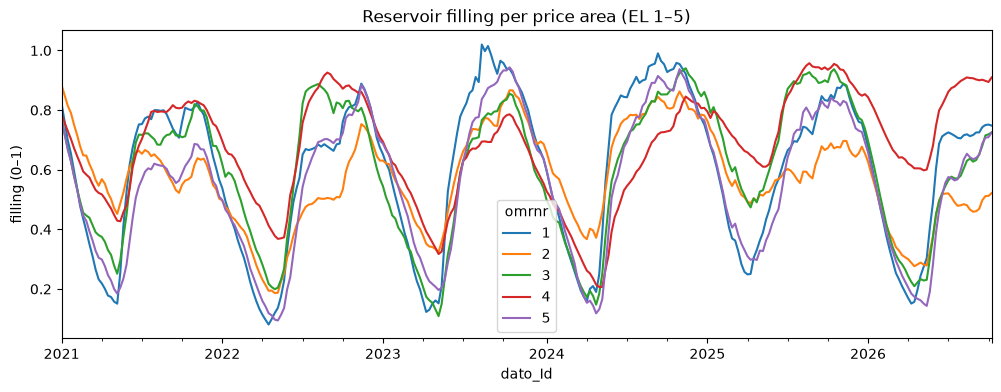

In [6]:
el[el["dato_Id"] >= "2021-01-01"].pivot_table(index="dato_Id", columns="omrnr", values="fyllingsgrad").plot(
    figsize=(12, 4), ylabel="filling (0–1)", title="Reservoir filling per price area (EL 1–5)"
);

## 4. Min / median / max per ISO week (seasonal reference)

Useful later as a feature: how far this week's filling is from the historical median.

In [7]:
mmm = pd.DataFrame(get("HentOffentligDataMinMaxMedian"))
mmm[mmm["omrType"] == "EL"].head(10)

,omrType,omrnr,iso_uke,minFyllingsgrad,minFyllingTWH,medianFyllingsGrad,medianFylling_TWH,maxFyllingsgrad,maxFyllingTWH
0,EL,1,1,0.456942,2.743146,0.619473,3.718857,0.759596,4.560054
1,EL,1,2,0.422610,2.537037,0.589710,3.540183,0.698276,4.191935
2,EL,1,3,0.389117,2.335971,0.556504,3.340840,0.655387,3.934459
3,EL,1,4,0.350204,2.102368,0.509039,3.055896,0.609225,3.657337
4,EL,1,5,0.318758,1.913585,0.464344,2.787577,0.570697,3.426046
5,EL,1,6,0.290989,1.746886,0.421190,2.528514,0.529107,3.176369
6,EL,1,7,0.257850,1.547939,0.375518,2.254335,0.498070,2.990048
7,EL,1,8,0.224144,1.345598,0.338356,2.031239,0.478421,2.872086
8,EL,1,9,0.192148,1.153518,0.300628,1.804749,0.432994,2.599379
9,EL,1,10,0.161222,0.967861,0.261119,1.567568,0.385575,2.314707


## Findings

Fill in, then copy the important ones to `docs/data-sources.md`:

- `omrnr` → NO1–NO5 mapping: `omrType == "EL"`, `omrnr` 1–5 = NO1–NO5 one to one. Ignore `NO` (whole country, `omrnr` 0) and `VASS` (river systems).
- History starts: 1995-01-08 (8 January, ISO week 1 of 1995) for all areas.
- Frequency, publish day: **weekly**, not hourly. One row per area per ISO week, `dato_Id` = the Sunday that ends the week. The next week is published on Wednesday at 13:00 (`neste_Publiseringsdato`), about 3 days after `dato_Id`.
- Gaps, duplicates: none. 0 duplicates, every step is exactly 7 days, 1658 weeks per area.
- How it would join to hourly prices: weekly → hourly forward-fill, yes. But fill from the **publish time** (Wednesday 13:00), not from `dato_Id`; otherwise the model sees reservoir data before it existed (leakage).
